# Backorder Prediction Using Machine Learning

**Python | Classification | Supply-Chain Early Warning**

In this project, we predict whether a product will go on backorder.

We will:
1. Check and understand the data.
2. Split the data into training and testing sets.
3. Fill missing values and convert text columns into numbers.
4. Train and compare Logistic Regression, Decision Tree, Random Forest, and a tuned Decision Tree.
5. Check the results using accuracy, precision, recall, and F1-score.
6. Identify important features and save the results.

The dataset has many more non-backorder cases than backorder cases, so we will pay special attention to recall. A model with high recall can catch more real backorders, but it may also create more false alarms.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## 2. Load the dataset

Keep `Training_Dataset_v2.csv` in the same folder as this notebook, or in your Google Drive if you use Colab.

In [4]:
## Load the dataset

# First, check whether the CSV is in the same folder as this notebook.
import os

file_path = "Training_Dataset_v2.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    # If using Google Colab, mount Google Drive and read the file from there.
    from google.colab import drive
    drive.mount('/content/drive')

    possible_paths = [
        "/content/drive/MyDrive/Training_Dataset_v2.csv",
        "/content/drive/MyDrive/Training_Dataset_v2.csv/Training_Dataset_v2.csv"
    ]
    file_path = next((path for path in possible_paths if os.path.exists(path)), None)
    if file_path is None:
        raise FileNotFoundError("Please place Training_Dataset_v2.csv beside this notebook or in Google Drive.")
    df = pd.read_csv(file_path)

print("Dataset loaded successfully")
df.head()

Mounted at /content/drive


In [6]:
df.head()

,sku,national_inv,lead_time,in_transit_qty,forecast_3_month,forecast_6_month,forecast_9_month,sales_1_month,sales_3_month,sales_6_month,...,pieces_past_due,perf_6_month_avg,perf_12_month_avg,local_bo_qty,deck_risk,oe_constraint,ppap_risk,stop_auto_buy,rev_stop,went_on_backorder
0,1026827,0,NaN,0,0,0,0,0,0,0,...,0,-99.00,-99.00,0,No,No,No,Yes,No,No
1,1043384,2,9.0,0,0,0,0,0,0,0,...,0,0.99,0.99,0,No,No,No,Yes,No,No
2,1043696,2,NaN,0,0,0,0,0,0,0,...,0,-99.00,-99.00,0,Yes,No,No,Yes,No,No
3,1043852,7,8.0,0,0,0,0,0,0,0,...,0,0.10,0.13,0,No,No,No,Yes,No,No
4,1044048,8,NaN,0,0,0,0,0,0,0,...,0,-99.00,-99.00,0,Yes,No,No,Yes,No,No


## 3. Check the data

In [7]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nData types and missing values:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (1048575, 23)

Column names:
Index(['sku', 'national_inv', 'lead_time', 'in_transit_qty',
       'forecast_3_month', 'forecast_6_month', 'forecast_9_month',
       'sales_1_month', 'sales_3_month', 'sales_6_month', 'sales_9_month',
       'min_bank', 'potential_issue', 'pieces_past_due', 'perf_6_month_avg',
       'perf_12_month_avg', 'local_bo_qty', 'deck_risk', 'oe_constraint',
       'ppap_risk', 'stop_auto_buy', 'rev_stop', 'went_on_backorder'],
      dtype='object')

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 23 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   sku                1048575 non-null  int64  
 1   national_inv       1048575 non-null  int64  
 2   lead_time          984057 non-null   float64
 3   in_transit_qty     1048575 non-null  int64  
 4   forecast_3_month   1048575 non-null  int64  
 5   foreca

## 4. Understand the target column

went_on_backorder
No     1039675
Yes       8900
Name: count, dtype: int64

Target percentage:
went_on_backorder
No     99.151229
Yes     0.848771
Name: proportion, dtype: float64


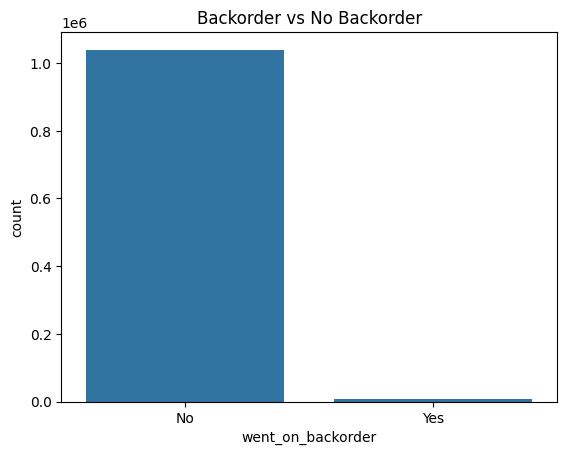

In [8]:
print(df["went_on_backorder"].value_counts())
print("\nTarget percentage:")
print(df["went_on_backorder"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="went_on_backorder")
plt.title("Backorder vs No Backorder")
plt.show()

## 5. Prepare the data

- `went_on_backorder` is the column we want to predict.
- `sku` is only a product ID, so we will not use it as a model feature.
- Convert Yes/No values to 1/0.

In [9]:
data = df.copy()

# Convert target values to 0 and 1
data["went_on_backorder"] = data["went_on_backorder"].astype(str).str.strip().str.lower()
data["went_on_backorder"] = data["went_on_backorder"].map({
    "no": 0, "yes": 1, "0": 0, "1": 1, "false": 0, "true": 1
})

# Remove rows where the target is missing or not recognized
data = data.dropna(subset=["went_on_backorder"])
data["went_on_backorder"] = data["went_on_backorder"].astype(int)

# Remove product ID if it exists
if "sku" in data.columns:
    data = data.drop(columns=["sku"])

# Convert Yes/No feature values to 1/0
for col in data.columns:
    if col != "went_on_backorder":
        data[col] = data[col].replace({
            "Yes": 1, "No": 0, "yes": 1, "no": 0,
            "YES": 1, "NO": 0
        })

X = data.drop(columns=["went_on_backorder"])
y = data["went_on_backorder"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

/tmp/ipykernel_734/3064111662.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[col] = data[col].replace({


Features shape: (1048575, 21)
Target shape: (1048575,)
went_on_backorder
0    1039675
1       8900
Name: count, dtype: int64


## 6. Split into training and testing data

We split before filling missing values. This prevents the test data from influencing the values used to fill missing data.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (838860, 21)
Testing data: (209715, 21)


## 7. Fill missing values

In [11]:
# Find numeric and text columns from the training data
numeric_cols = X_train.select_dtypes(include=["number", "bool"]).columns
text_cols = X_train.select_dtypes(exclude=["number", "bool"]).columns

# Fill numeric missing values using training median
for col in numeric_cols:
    median_value = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# Fill text missing values using the most common training value
for col in text_cols:
    mode_value = X_train[col].mode()
    if len(mode_value) > 0:
        most_common = mode_value[0]
        X_train[col] = X_train[col].fillna(most_common)
        X_test[col] = X_test[col].fillna(most_common)

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


## 8. Convert text columns into numbers

Machine learning models need numeric input. `get_dummies()` converts text categories into numeric columns. We then make sure training and testing data have the same columns.

In [12]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# Keep the same columns in both sets
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

print("Training columns:", X_train.shape[1])
print("Testing columns:", X_test.shape[1])

Training columns: 21
Testing columns: 21


## 9. Train and evaluate models

The dataset has far fewer backorder cases than non-backorder cases. Accuracy alone can be misleading, so we will also check precision, recall, and F1-score.

- **Recall:** how many real backorders the model finds.
- **Precision:** how many predicted backorders are actually backorders.
- **F1-score:** balance between precision and recall.

In [13]:
results = []
trained_models = {}

def check_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })
    trained_models[name] = model

    print("\n", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-score:", round(f1, 4))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

### 9.1 Logistic Regression

In [14]:
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
check_model("Logistic Regression", lr_model)


 Logistic Regression
Accuracy: 0.5218
Precision: 0.0147
Recall: 0.8399
F1-score: 0.029
Confusion matrix:
[[107934 100001]
 [   285   1495]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 9.2 Decision Tree

In [15]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)
check_model("Decision Tree", dt_model)


 Decision Tree
Accuracy: 0.8664
Precision: 0.0531
Recall: 0.8764
F1-score: 0.1002
Confusion matrix:
[[180138  27797]
 [   220   1560]]


### 9.3 Random Forest

In [16]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
check_model("Random Forest", rf_model)


 Random Forest
Accuracy: 0.9432
Precision: 0.1083
Recall: 0.7876
F1-score: 0.1904
Confusion matrix:
[[196392  11543]
 [   378   1402]]


### 9.4 Tune the Decision Tree

We use RandomizedSearchCV to try a few Decision Tree settings. It uses the training data to find settings that improve recall.

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Decision Tree hyperparameter tuning
dt = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

param_grid = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [1, 5, 10, 20],
    "criterion": ["gini", "entropy"]
}

dt_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_grid,
    n_iter=12,
    scoring="recall",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_search.fit(X_train, y_train)

best_dt = dt_search.best_estimator_

print("Best parameters:", dt_search.best_params_)

# Evaluate once on the held-out test data
y_pred_tuned = best_dt.predict(X_test)

print("\nTuned Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tuned, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_tuned, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'min_samples_split': 20, 'min_samples_leaf': 20, 'max_depth': 5, 'criterion': 'entropy'}

Tuned Decision Tree Results
Accuracy: 0.8510550032186539
Precision: 0.046663383403102686
Recall: 0.851685393258427
F1-score: 0.08847904750787908

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92    207935
           1       0.05      0.85      0.09      1780

    accuracy                           0.85    209715
   macro avg       0.52      0.85      0.50    209715
weighted avg       0.99      0.85      0.91    209715

Confusion Matrix:
[[176963  30972]
 [   264   1516]]


In [26]:
# Add the tuned model to the model comparison
trained_models["Tuned Decision Tree"] = best_dt

results.append({
    "Model": "Tuned Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
    "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_tuned, zero_division=0)
})

print("Tuned Decision Tree added to the comparison.")

                 Model  Accuracy  Precision    Recall  F1-score
0        Decision Tree  0.866404   0.053139  0.876404  0.100202
1  Logistic Regression  0.521799   0.014730  0.839888  0.028952
2        Random Forest  0.943156   0.108304  0.787640  0.190424
3  Tuned Decision Tree  0.851055   0.046663  0.851685  0.088479

Updated comparison saved successfully!


## 10. Compare the models

In [17]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by=["Recall", "F1-score"],
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.866404,0.053139,0.876404,0.100202
1,Logistic Regression,0.521799,0.014730,0.839888,0.028952
2,Random Forest,0.943156,0.108304,0.787640,0.190424


## 11. Select the best model

For this project, we first look for higher recall because we want to identify as many real backorders as possible. We also check precision and F1-score before explaining the result.

In [18]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

best_predictions = best_model.predict(X_test)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, best_predictions))

Selected model: Decision Tree

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.87      0.93    207935
           1       0.05      0.88      0.10      1780

    accuracy                           0.87    209715
   macro avg       0.53      0.87      0.51    209715
weighted avg       0.99      0.87      0.92    209715


Confusion matrix:
[[180138  27797]
 [   220   1560]]


## 12. Feature importance (Decision Tree / Random Forest)

forecast_3_month     0.443354
national_inv         0.269561
sales_1_month        0.060668
sales_3_month        0.035272
forecast_9_month     0.033793
perf_6_month_avg     0.024897
lead_time            0.022658
in_transit_qty       0.020955
sales_9_month        0.020616
sales_6_month        0.018242
perf_12_month_avg    0.016908
min_bank             0.010054
forecast_6_month     0.008537
deck_risk            0.005829
local_bo_qty         0.003347
dtype: float64


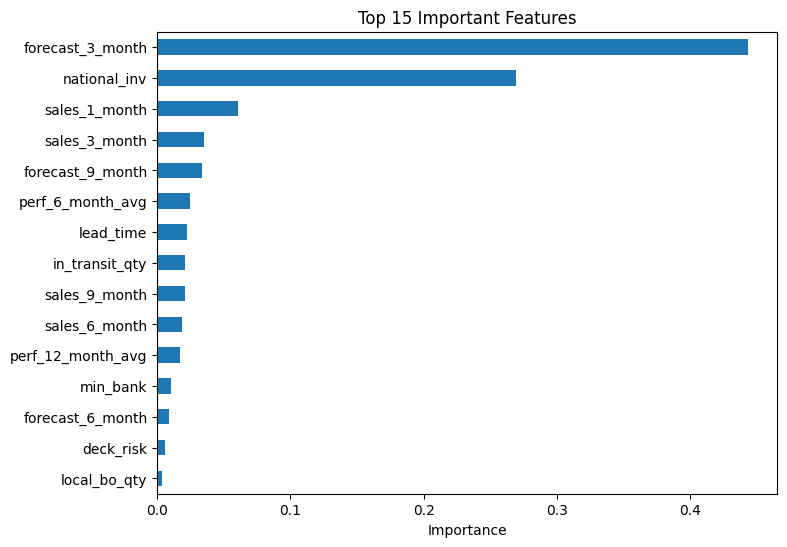

In [19]:
if best_model_name in ["Decision Tree", "Random Forest", "Tuned Decision Tree"]:
    importance = pd.Series(
        best_model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=False)

    print(importance.head(15))

    importance.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
    plt.title("Top 15 Important Features")
    plt.xlabel("Importance")
    plt.show()
else:
    print("Feature importance plot is available here for Decision Tree or Random Forest.")

## 13. Save the results

In [20]:
results_df.to_csv("backorder_model_comparison.csv", index=False)
print("Model comparison saved to backorder_model_comparison.csv")

Model comparison saved to backorder_model_comparison.csv


## 14. Business conclusion

Use the results from the table and classification report above to write the final conclusion. Do not copy expected metrics from another run because the results depend on the dataset and code execution.

In this problem:
- A false negative means the model misses a real backorder.
- A false positive means the model warns about a backorder that does not happen.
- Higher recall can help the supply-chain team identify more potential backorders, but low precision may create extra alerts.

**Limitation:** The dataset is highly imbalanced, and the model should be tested further before being used for real supply-chain decisions.

In [21]:
import joblib

joblib.dump(best_model, "backorder_best_model.pkl")
print("Selected model saved successfully as backorder_best_model.pkl")

Decision Tree model saved successfully!


## Final notes

- The split is stratified so the training and testing data keep a similar percentage of backorders.
- Missing values are filled using values calculated from the training data only.
- The test results can change if the data or code changes.
- Before uploading to GitHub, run all cells from top to bottom and make sure there are no errors.